# Kalimantan FIRMS fire alerts and fire count grid, August to October 2026

Plots the Kalimantan provinces on a basemap, the FIRMS fire alerts made by `job/firms` (VIIRS and MODIS near real time, clipped to each province), and the fire count grid made by `job/firms_grid` (number of alerts per cell, with sea, outside Kalimantan and WorldCover water masked), and the number of alerts per regency and city (admin level 2).

In [1]:
import os

os.chdir(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebook" else os.getcwd())

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from dotenv import load_dotenv
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter

# override=True so the .env credentials win over anything already in the environment
load_dotenv(override=True)

# Lower resolution figures, keeps the notebook small
plt.rcParams["figure.dpi"] = 60

AOI_URL = "/vsicurl/https://storage.googleapis.com/gee-ramiqcom-bucket/admin/indonesia_adm_level_1.fgb"
AOI2_URL = "/vsicurl/https://storage.googleapis.com/gee-ramiqcom-bucket/admin/indonesia_adm_level_2.fgb"

# Kalimantan provinces only
AOI_FILTER = "WADMPR LIKE 'Kalimantan%'"
CLOUD_PREFIX = "gs://gee-ramiqcom-s4g-bucket/forest_fire_indonesian_2026"
PROVINCES = ["kalimantan_barat", "kalimantan_tengah", "kalimantan_selatan", "kalimantan_timur", "kalimantan_utara"]
DATE_NAME = "2026-08_2026-10"
FIRMS_PATHS = {name: f"{CLOUD_PREFIX}/firms/{name}_{DATE_NAME}.fgb" for name in PROVINCES}
GRID_PATH = f"{CLOUD_PREFIX}/firms_grid/kalimantan_{DATE_NAME}.tif"

## Map helpers

In [2]:
def add_lonlat(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"))
    ax.tick_params(labelsize=8)
    ax.grid(color="white", linewidth=0.4, alpha=0.6, linestyle="--")


def add_north_arrow(ax, x=0.94, y=0.92):
    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - 0.1),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(facecolor="black", edgecolor="white", width=4, headwidth=12),
    )


def add_scalebar(ax, x=0.05, y=0.05):
    # Axes are in degrees, so convert km to degrees of longitude at the map's center latitude
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    km_per_deg = 111.32 * np.cos(np.radians((ymin + ymax) / 2))
    width_km = (xmax - xmin) * km_per_deg
    length_km = next(n for n in (200, 100, 50, 20, 10, 5, 2, 1, 0.5) if n <= width_km / 4)
    length_deg = length_km / km_per_deg

    x0 = xmin + x * (xmax - xmin)
    y0 = ymin + y * (ymax - ymin)
    height = (ymax - ymin) * 0.012
    for i in range(2):
        ax.add_patch(
            plt.Rectangle(
                (x0 + i * length_deg / 2, y0),
                length_deg / 2,
                height,
                facecolor="black" if i == 0 else "white",
                edgecolor="black",
                linewidth=0.8,
            )
        )
    for frac in (0, 0.5, 1):
        ax.text(
            x0 + frac * length_deg,
            y0 + height * 1.6,
            f"{length_km * frac:g}",
            ha="center",
            va="bottom",
            fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
        )
    ax.text(x0 + length_deg + (xmax - xmin) * 0.01, y0, "km", va="bottom", fontsize=8)


def set_extent(ax, gdf, pad_frac=0.03):
    xmin, ymin, xmax, ymax = gdf.total_bounds
    pad = pad_frac * max(xmax - xmin, ymax - ymin)
    ax.set_xlim(xmin - pad, xmax + pad)
    ax.set_ylim(ymin - pad, ymax + pad)


def decorate(ax, title):
    add_lonlat(ax)
    add_north_arrow(ax)
    add_scalebar(ax)
    ax.set_title(title)

## 1. Kalimantan provinces

Province boundaries from the Indonesian admin level 1 file, the same source and filter as the jobs. The file stores each province as many polygon parts, dissolved here into one shape per province.

In [3]:
provinces = gpd.read_file(AOI_URL, where=AOI_FILTER, columns=["KDPPUM", "WADMPR"])
provinces = provinces.dissolve(by=["KDPPUM", "WADMPR"]).reset_index().to_crs("EPSG:4326")
provinces[["KDPPUM", "WADMPR"]]

,KDPPUM,WADMPR
0,61,Kalimantan Barat
1,62,Kalimantan Tengah
2,63,Kalimantan Selatan
3,64,Kalimantan Timur
4,65,Kalimantan Utara


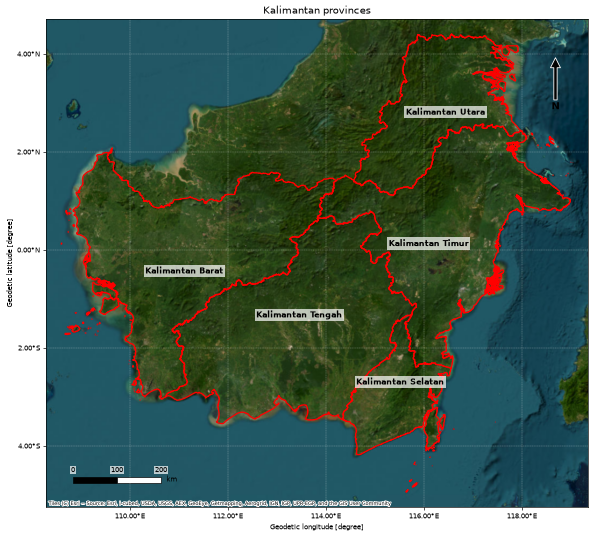

In [4]:
fig, ax = plt.subplots(figsize=(10, 10))

provinces.boundary.plot(ax=ax, color="red", linewidth=1.5)
for _, row in provinces.iterrows():
    point = row.geometry.representative_point()
    ax.text(
        point.x,
        point.y,
        row["WADMPR"],
        ha="center",
        fontsize=9,
        fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=2),
    )

set_extent(ax, provinces)
cx.add_basemap(ax, crs=provinces.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6)
decorate(ax, "Kalimantan provinces")

plt.tight_layout()
plt.show()

## 2. FIRMS fire alerts

All alerts from the five province files. Each point is the centre of a satellite pixel with an active fire detection (375 m for VIIRS, 1 km for MODIS), not a burned area. MODIS near real time has no data for early August, so MODIS points cover only part of the period.

In [5]:
firms = pd.concat(
    [
        gpd.read_file(path, columns=["acq_date", "instrument", "satellite"]).assign(province=name)
        for name, path in FIRMS_PATHS.items()
    ],
    ignore_index=True,
)
firms = gpd.GeoDataFrame(firms, crs="EPSG:4326")

print(f"{len(firms):,} alerts, {firms['acq_date'].min()} to {firms['acq_date'].max()}")
firms.groupby(["province", "instrument"]).size().unstack(fill_value=0)

956,066 alerts, 2026-08-01 to 2026-10-31


instrument,MODIS,VIIRS
province,,
kalimantan_barat,9260,220986
kalimantan_selatan,4049,80366
kalimantan_tengah,29040,507408
kalimantan_timur,5728,90828
kalimantan_utara,200,8201


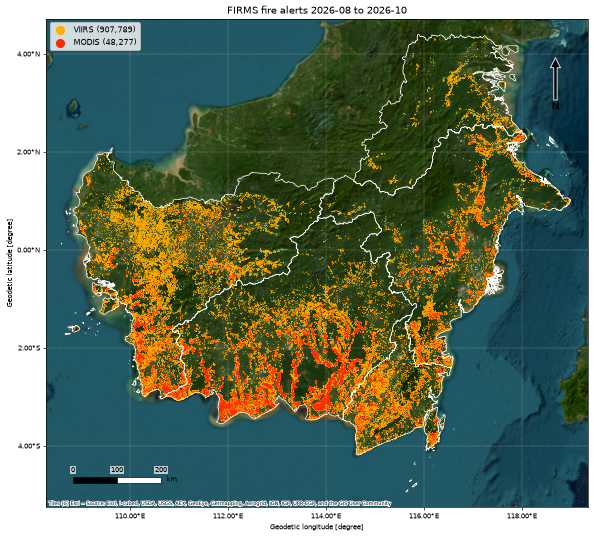

In [6]:
INSTRUMENT_COLORS = {"VIIRS": "#ffb000", "MODIS": "#ff2a00"}

fig, ax = plt.subplots(figsize=(10, 10))

# Scatter on the raw coordinates, much faster than GeoDataFrame.plot for close to a million points
for instrument, color in INSTRUMENT_COLORS.items():
    points = firms[firms["instrument"] == instrument]
    ax.scatter(
        points.geometry.x,
        points.geometry.y,
        s=0.3,
        color=color,
        linewidths=0,
        label=f"{instrument} ({len(points):,})",
        rasterized=True,
    )
provinces.boundary.plot(ax=ax, color="white", linewidth=0.8)

set_extent(ax, provinces)
cx.add_basemap(ax, crs=provinces.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6)
decorate(ax, f"FIRMS fire alerts {DATE_NAME.replace('_', ' to ')}")
ax.legend(loc="upper left", markerscale=20, fontsize=9)

plt.tight_layout()
plt.show()

## 3. Fire count grid

Number of FIRMS alerts per grid cell from `job/firms_grid`. The grid count only includes alerts within half a cell from the cell centre, so it counts fewer alerts than the points above. Cells with no alerts (0) are shown as no data, as are the masked sea, outside Kalimantan and WorldCover water cells. Log color scale because a few cells have far more alerts than the rest.

In [7]:
with rasterio.open(GRID_PATH) as src:
    grid = src.read(1)
    bounds = src.bounds
    nodata = src.nodata
    resolution = src.res

grid_extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)
# Masked cells and cells without alerts are not shown
fire_count = np.ma.masked_where((grid == nodata) | (grid == 0), grid)

print(f"Cell size {resolution[0]:.4f}°, {fire_count.count():,} cells with alerts")
print(f"{int(fire_count.sum()):,} alerts counted, max {fire_count.max()} per cell")

Cell size 0.0090°, 88,055 cells with alerts
749,840 alerts counted, max 721 per cell


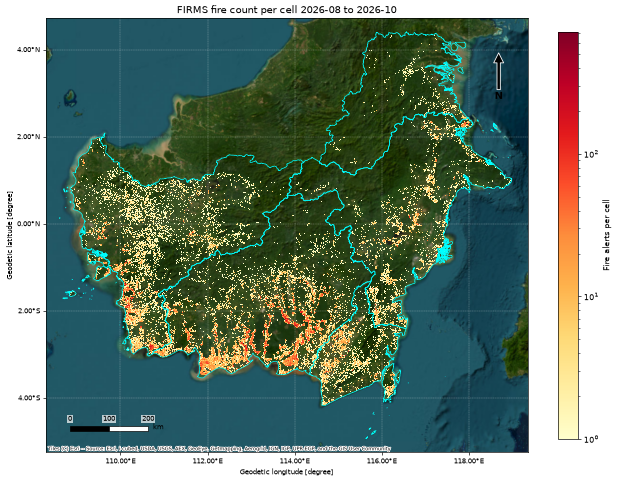

In [8]:
fig, ax = plt.subplots(figsize=(11, 10))

image = ax.imshow(
    fire_count,
    extent=grid_extent,
    cmap="YlOrRd",
    norm=LogNorm(vmin=1, vmax=fire_count.max()),
    interpolation="nearest",
    zorder=2,
)
provinces.boundary.plot(ax=ax, color="cyan", linewidth=0.8, zorder=3)

set_extent(ax, provinces)
cx.add_basemap(ax, crs=provinces.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6, zorder=1)
decorate(ax, f"FIRMS fire count per cell {DATE_NAME.replace('_', ' to ')}")
fig.colorbar(image, ax=ax, shrink=0.7, label="Fire alerts per cell")

plt.tight_layout()
plt.show()

## 4. Fire alerts per regency and city

Regency and city boundaries (kabupaten and kota) from the Indonesian admin level 2 file, with the same Kalimantan filter. Each FIRMS alert is assigned to the regency it falls in, so every alert is counted, unlike the grid above. Regencies differ a lot in size, so the alerts per 100 km² are shown next to the total count, with the area computed in an equal area projection (EPSG:6933).

In [9]:
regencies = gpd.read_file(AOI2_URL, where=AOI_FILTER, columns=["KDPKAB", "KDPPUM", "WADMKK", "WADMPR"])
regencies = regencies.dissolve(by=["KDPKAB", "KDPPUM", "WADMKK", "WADMPR"]).reset_index().to_crs("EPSG:4326")

alerts = firms[["instrument", "geometry"]].sjoin(regencies[["KDPKAB", "geometry"]], predicate="within")
counts = alerts.groupby(["KDPKAB", "instrument"]).size().unstack(fill_value=0)

regencies = regencies.merge(counts, left_on="KDPKAB", right_index=True, how="left")
regencies[["VIIRS", "MODIS"]] = regencies[["VIIRS", "MODIS"]].fillna(0).astype(int)
regencies["alerts"] = regencies["VIIRS"] + regencies["MODIS"]
regencies["area_km2"] = regencies.to_crs("EPSG:6933").area / 1e6
regencies["alerts_per_100km2"] = regencies["alerts"] / regencies["area_km2"] * 100

# Alerts near the coast or on borders can fall outside every admin level 2 polygon
print(f"{len(regencies)} regencies and cities, {regencies['alerts'].sum():,} of {len(firms):,} alerts assigned")
regencies.sort_values("alerts", ascending=False)[
    ["WADMKK", "WADMPR", "VIIRS", "MODIS", "alerts", "area_km2", "alerts_per_100km2"]
].head(15).round(1)

56 regencies and cities, 956,066 of 956,066 alerts assigned


,WADMKK,WADMPR,VIIRS,MODIS,alerts,area_km2,alerts_per_100km2
3,Ketapang,Kalimantan Barat,131369,6621,137990,30018.7,459.7
24,Pulang Pisau,Kalimantan Tengah,97928,6118,104046,9650.9,1078.1
16,Kapuas,Kalimantan Tengah,73694,3912,77606,17041.2,455.4
15,Kotawaringin Timur,Kalimantan Tengah,71439,3827,75266,15543.8,484.2
20,Seruyan,Kalimantan Tengah,65397,3960,69357,15215.2,455.8
19,Katingan,Kalimantan Tengah,48447,3039,51486,20382.3,252.6
14,Kotawaringin Barat,Kalimantan Tengah,48409,2997,51406,9480.3,542.2
27,Kota Palangkaraya,Kalimantan Tengah,46344,1784,48128,2848.7,1689.5
41,Paser,Kalimantan Timur,23770,1665,25435,10767.4,236.2
42,Kutai Kartanegara,Kalimantan Timur,21417,1428,22845,26926.5,84.8


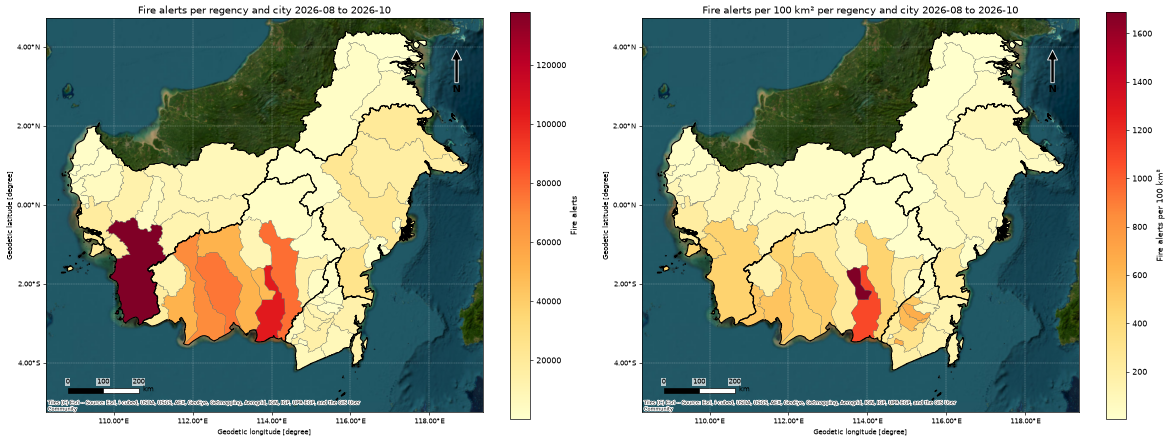

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

for ax, (column, label, cmap) in zip(
    axes,
    [
        ("alerts", "Fire alerts", "YlOrRd"),
        ("alerts_per_100km2", "Fire alerts per 100 km²", "YlOrRd"),
    ],
):
    regencies.plot(
        ax=ax,
        column=column,
        cmap=cmap,
        edgecolor="grey",
        linewidth=0.3,
        legend=True,
        legend_kwds=dict(shrink=0.7, label=label),
        zorder=2,
    )
    provinces.boundary.plot(ax=ax, color="black", linewidth=1.2, zorder=3)

    set_extent(ax, provinces)
    cx.add_basemap(ax, crs=provinces.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6, zorder=1)
    decorate(ax, f"{label} per regency and city {DATE_NAME.replace('_', ' to ')}")

plt.tight_layout()
plt.show()